# Econ 5200 PS2 — The Underpowered Portfolio

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 5-8 · 100 points · your role: Experimentation lead, consulting engagement

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is experimentation lead's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning.



## Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: Reconstruct the Portfolio (30 pts)

### Step 1.1: Simulate the experiment programme (15 pts)

estimate =  true effect + noise

In [ ]:
# ---- Step 1.1: parameters (every planted setting is set HERE) ----
SEED = 42
N_EXPERIMENTS = 200
SIGMA = 1.0          # person-to-person standard deviation for revenue gained during assigned test (effects are in sigma units)
P_DUD = 0.80         # 80% of ideas do nothing, and 20% really work. This base rate is what makes false wins common. If most ideas worked, few wins would be flukes.
DUD_SD = 0.01
REAL_MIN = 0.03
REAL_SCALE = 0.07
N_MIN, N_MAX = 50, 2_000
ALPHA = 0.05
ZERO_BAND = 0.03


def simulate_portfolio(n=N_EXPERIMENTS, seed=SEED):
    """Simulate n experiments and return a log with the true effect attached."""
    gen = np.random.default_rng(seed)

    is_real = gen.random(n) >= P_DUD
    true_effect = np.where(
        is_real,
        REAL_MIN + gen.exponential(REAL_SCALE, n),
        gen.normal(0.0, DUD_SD, n),
    )

    n_per_arm = np.exp(gen.uniform(np.log(N_MIN), np.log(N_MAX), n)).round().astype(int)

    se = SIGMA * np.sqrt(2.0 / n_per_arm)
    estimate = true_effect + gen.normal(0.0, se)
    z = estimate / se
    p_value = 2 * stats.norm.sf(np.abs(z))


    power = stats.norm.sf(stats.norm.isf(ALPHA / 2) - (REAL_MIN + REAL_SCALE) / se)

    return pd.DataFrame({
        "is_real": is_real, "true_effect": true_effect, "n_per_arm": n_per_arm,
        "se": se, "estimate": estimate, "z": z, "p_value": p_value, "power": power,
        "essentially_zero": np.abs(true_effect) < ZERO_BAND,
    })


log = simulate_portfolio()

print(f"{len(log)} experiments | real: {log['is_real'].sum()} | duds: {(~log['is_real']).sum()}")
print("Power ranges from", round(log["power"].min(), 2), "to", round(log["power"].max(), 2),
      "| median", round(log["power"].median(), 2))
log.head()

200 experiments | real: 35 | duds: 165
Power ranges from 0.07 to 0.88 | median 0.22


,is_real,true_effect,n_per_arm,se,estimate,z,p_value,power,essentially_zero
0,False,5.242e-03,385,0.072,0.002,0.022,9.828e-01,0.283,True
1,False,2.763e-03,558,0.060,-0.002,-0.034,9.732e-01,0.386,True
2,True,1.062e-01,1789,0.033,0.166,4.974,6.546e-07,0.849,False
3,False,-2.310e-02,1889,0.033,0.006,0.184,8.538e-01,0.867,True
4,False,5.435e-04,145,0.117,0.002,0.016,9.872e-01,0.134,True



Purpose: I started by simulating 200 A/B tests in which I choose the true effect of every idea. The client only ever gets to see a noisy estimate, but because I record the truth I can later check whether their decisions were right, given that I know the truth behind each test. Effects are measured in units of σ = 1, which in actuality is the typical spread of individual visitors' revenue around the average visitor, so an effect of 0.10 means the new page raises average revenue by a tenth of that spread.

The prior: P_DUD = 0.80, which means 80% of ideas are duds. This base rate matters because if most ideas worked, the likelihood is that few wins would be flukes and most would have a real effect. About 80% of true effects are therefore essentially zero (within ±0.03), since the minimum assigned to a real idea is 0.03 (not including the bonus). I drew each dud's true effect from a Normal(0, 0.01) distribution: a tiny number centred on zero, some slightly negative and some slightly positive. The other 20% are real. A real idea's true effect is 0.03 plus a random extra drawn from an Exponential distribution with mean 0.07, so every real effect is at least 0.03 and they average 0.10. The extra captures that real ideas differ in how much they help: most help a little and a few help a lot. The code first decides real or dud for each idea with a random draw, then assigns the matching true effect. This label is part of the hidden truth, so it is set before any test is run and has nothing to do with the p-value or threshold.

Sample size: Each experiment gets one group size (the same for both arms) between 50 and 2,000 people, drawn evenly on a log scale. A plain random draw would make most tests large, because most numbers between 50 and 2,000 are large. The log scale gives each doubling about the same share (50 to 100 is about as common as 800 to 1,600), so the portfolio contains many small, noisy tests as well as large precise ones. This is what makes power vary.

Noise and the estimate: SE = σ√(2/n) is the typical size of the luck in a test's result. It is larger when people differ more (σ) and smaller when there are more people (n), and since there are two groups the factor is 2. Each experiment has its own SE because each has its own n. The estimate is the true effect plus noise, where the noise is drawn from a bell curve centred on zero with that test's SE. This is what the client would actually observe: the truth plus luck, with luck of either sign.

z-score and p-value: z = estimate ÷ SE measures the result in units of its own noise. The two-sided p-value is the chance that, if the idea did nothing, luck alone would give a z at least this far from zero in either direction.

Power: For each test I compute the chance that it would detect a typical real effect (0.10) at p < 0.05. It uses one typical effect for every test so that power depends only on the test's design (its SE), not on whether the idea happens to be real. I use it in Phase 2 to split tests into low, medium and high power.

Check: The portfolio has 35 real ideas and 165 duds (seed 42), and power ranges from about 0.07 to 0.88 with a median of 0.22, so most tests are underpowered. I chose these settings so that the portfolio is underpowered, and the conclusions depend on that assumption.

### Step 1.2: Apply the client's rule (15 pts)

In [ ]:

log["shipped"] = (log["p_value"] < ALPHA) & (log["estimate"] > 0)
won = log[log["shipped"]]

n_shipped = int(log["shipped"].sum())

false_ship_share = won["essentially_zero"].mean()


mean_true_shipped = won["true_effect"].mean()

mean_est_shipped = won["estimate"].mean()

inflation = mean_est_shipped / mean_true_shipped


print(f"Shipped:                          {n_shipped} of {len(log)}")
print(f"False-ship share:                 {false_ship_share:.1%}")
print(f"Mean TRUE effect (shipped):       {mean_true_shipped:.4f}")
print(f"Mean ESTIMATED effect (shipped):  {mean_est_shipped:.4f}")
print(f"Gap (estimate - truth):           {mean_est_shipped - mean_true_shipped:.4f}  -> x{inflation:.2f}")

log["noise"] = log["estimate"] - log["true_effect"]       # the luck in each result
print(f"\nMean noise, all experiments:      {log['noise'].mean():+.4f}")
print(f"Mean noise, shipped only:         {log.loc[log['shipped'], 'noise'].mean():+.4f}")

Shipped:                          11 of 200
False-ship share:                 18.2%
Mean TRUE effect (shipped):       0.1397
Mean ESTIMATED effect (shipped):  0.2267
Gap (estimate - truth):           0.0871  -> x1.62

Mean noise, all experiments:      -0.0055
Mean noise, shipped only:         +0.0871


The clients rule: The client ships an experiment when its two-sided p-value is below 0.05 and its estimate is positive ( even if a loss implies signifcance it wouldn't be shipped since the goal is to maimise revenue). I apply this rule to the portfolio and then use the true effects, which the client never sees, to audit the decisions.

Experiments that were shipped: 11 of the 200 experiments ship. Of those, 9 are real ideas and 2 of them have an essentially zero true effect, so they cleared the bar almost entirelydue to noise rather thna an actual effect. These are the false ships.

Experiments of the sipped which had true effects: Among the shipped experiments the average true effect is 0.140, but the average estimated effect is 0.227. Between the estinate and purely the true effect the gap is 0.087, so that implies the shipped experiments look about 1.6 times better than they actually are.

Why the gap dxists: The phenonmena behind why the gap exists is knwon as the winners cruse. For instance in this case the client observes only estimates, and an estimate is the true effect plus luck. Shipping selects the experiments whose estimate cleared the threshold. However among those its very likely that luck leaned them upward. When we check the noise check we can see this happening. Across all 200 experiments the average noise (estimate − truth) is −0.006, about zero as it should be, but among the shipped experiments it is +0.087. The selection process is inherently favouring the lucky ones rather than rewarding purely on merit. Phase 2 explains why this is strongest for low-powered tests and measures it.

## Phase 2: The Winner's Curse (35 pts)

### Step 2.1: Quantify the exaggeration (20 pts)

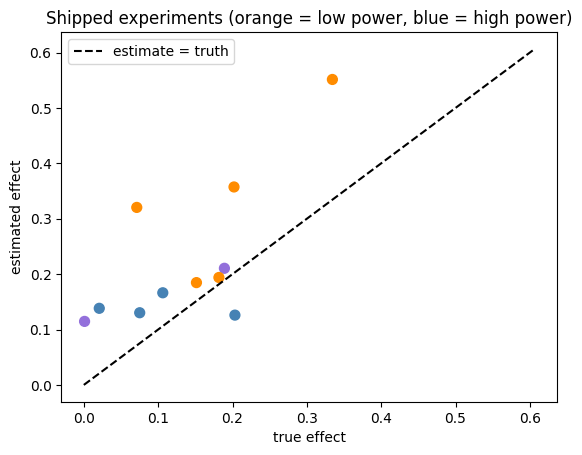

Overall inflation: x1.62


,shipped,mean_true,mean_estimate,inflation
tier,,,,
low,5,0.188,0.322,1.709
medium,2,0.095,0.163,1.711
high,4,0.101,0.140,1.384


In [ ]:
# ---- Step 2.1: inflation, overall and by power tier ----
TIER_BINS = [0, 0.25, 0.50, 1.0]
TIER_LABELS = ["low", "medium", "high"]
log["tier"] = pd.cut(log["power"], TIER_BINS, labels=TIER_LABELS)
won = log[log["shipped"]]

# plot: shipped experiments, estimate vs truth (above the line = exaggerated)
colors = won["tier"].map({"low": "darkorange", "medium": "mediumpurple", "high": "steelblue"})
plt.scatter(won["true_effect"], won["estimate"], c=colors, s=50)
top = max(won["estimate"].max(), won["true_effect"].max()) * 1.1
plt.plot([0, top], [0, top], "k--", label="estimate = truth")
plt.xlabel("true effect"); plt.ylabel("estimated effect")
plt.title("Shipped experiments (orange = low power, blue = high power)")
plt.legend(); plt.show()

# inflation = mean estimate / mean true effect, among shipped
table = won.groupby("tier", observed=True).agg(
    shipped=("true_effect", "size"),
    mean_true=("true_effect", "mean"),
    mean_estimate=("estimate", "mean"),

)
table["inflation"] = table["mean_estimate"] / table["mean_true"]
print(f"Overall inflation: x{inflation:.2f}")
table

In [ ]:
# Now the same table, averaged over 500 portfolios
# one portfolio only has 11 winners, so I repeat the experiment 500 times and pool the winners
winners = []
for s in range(500):
    d = simulate_portfolio(N_EXPERIMENTS, seed=s)                      # a fresh portfolio each time
    d["tier"] = pd.cut(d["power"], TIER_BINS, labels=TIER_LABELS)      # same power tiers as above
    winners.append(d[(d["p_value"] < ALPHA) & (d["estimate"] > 0)])    # the client's rule
winners = pd.concat(winners)
table500 = winners.groupby("tier", observed=True).agg(
    shipped=("true_effect", "size"),
    mean_true=("true_effect", "mean"),
    mean_estimate=("estimate", "mean"),
)
table500["inflation"] = table500["mean_estimate"] / table500["mean_true"]
print(table500)

        shipped  mean_true  mean_estimate  inflation
tier                                                
low        2760      0.107          0.310      2.901
medium     2126      0.120          0.189      1.574
high       3488      0.114          0.144      1.260


The setup: I sort the experiments into brackets of power which are low, medium and high power. The thresholds for eahc brakcet are 0–25% (low), 25–50% (medium) and 50–100% (high).Power here is the chance a test would detect a typical real effect appproximately (0.10), so it depends only on the sample size, not on whether this particular idea is real. Within each group I compare what the shipped experiments looked like (the average estimate) with what they really were (the average true effect).

What I found: With seed 42, the low-power winners look about 1.7 times better than they really are, the medium-power winners also about 1.7 times, and the high-power winners about 1.4 times. So we can conclude inflation is highest at low power and lowest at high power in this experiment. This is only a handful of experiments, though (11 shipped in total, and just 2 in the medium group), so I don't read much into one portfolio. However when a similar expirement is averaged over 500 portfolios the pattern is much clearer. The low power winners look about 2.9 times better with 1.6 at medium and 1.3 at high. Had we not averaged out the experiments conclsuions over 500 portoflios we would not hav eknown about the inflationary gap between the medium bracket and low bracket.

Why this occurs: An estimate is the true effect plus noise. So in this case A low-powered test will have a lot of noise, and to get past p < 0.05 the estimate has to land far from zero. So for the test who have a small or an essentially zero true effect, the only way to get there is making up for what they dont have in ture effect with a larger noise value. So among the low-powered winners, much of the estimate is associated with luck. A high-powered test has little noise, so it doesn't need a larger noise value so that they can clear the bar. Their true effect itself is sufficient . Shipping keeps only the experiments that cleared the bar, therefore it's inhrently going to favour and keep lucky tests who were inflated by noise. That is why the winner's curse is strongest at low power.

### Step 2.2: The bootstrap where the formula fails (15 pts)

In [ ]:
# ---- Step 2.2: bootstrap the realised return ----
# Realised return = sum of the TRUE effects of the shipped experiments.
true_eff = log["true_effect"].to_numpy()
ship = log["shipped"].to_numpy()
n_exp = len(log)
realised_return = true_eff[ship].sum()
print(f"Realised return (observed portfolio): {realised_return:.4f}")

# (1) MY OWN LOOP: resample the 200 experiments with replacement, recompute the sum.
B = 10_000
boot_rng = np.random.default_rng(SEED)          # fixed seed so this cell reruns identically
boot_stats = np.empty(B)
for b in range(B):
    idx = boot_rng.integers(0, n_exp, size=n_exp)
    boot_stats[b] = true_eff[idx][ship[idx]].sum()

boot_se = boot_stats.std(ddof=1)
pct_lo, pct_hi = np.percentile(boot_stats, [2.5, 97.5])
print(f"My loop: bootstrap SE = {boot_se:.4f},  95% percentile interval = [{pct_lo:.4f}, {pct_hi:.4f}]")

# (2) scipy check. paired=True keeps each experiment's truth and ship flag together.
def stat(t, s, axis=-1):
    return np.sum(t * s, axis=axis)

res_bca = stats.bootstrap((true_eff, ship.astype(float)), stat, paired=True, vectorized=True,
                          n_resamples=B, confidence_level=0.95, method="BCa",
                          random_state=np.random.default_rng(SEED))
res_pct = stats.bootstrap((true_eff, ship.astype(float)), stat, paired=True, vectorized=True,
                          n_resamples=B, confidence_level=0.95, method="percentile",
                          random_state=np.random.default_rng(SEED + 1))
print(f"scipy:bootstrap SE = {res_bca.standard_error:.4f}")
print(f"scipy percentile interval = [{res_pct.confidence_interval.low:.4f}, {res_pct.confidence_interval.high:.4f}]   (should match my loop)")
print(f"scipy BCa interval        = [{res_bca.confidence_interval.low:.4f}, {res_bca.confidence_interval.high:.4f}]   <- the one I report")

# (3) failure-mode checks
contrib = np.sort(true_eff[ship])[::-1]
print("\nFailure-mode checks")
print(f"shipped experiments driving the sum:        {ship.sum()}")
print(f"share of the sum from the single largest:    {contrib[0] / contrib.sum():.1%}")
print(f"distinct bootstrap values / {B}:           {len(np.unique(boot_stats.round(10)))}")
print(f"skewness of bootstrap distribution:          {stats.skew(boot_stats):.3f}")

Realised return (observed portfolio): 1.5363
My loop: bootstrap SE = 0.5472,  95% percentile interval = [0.5884, 2.7170]
scipy:bootstrap SE = 0.5472
scipy percentile interval = [0.5966, 2.7036]   (should match my loop)
scipy BCa interval        = [0.7307, 3.0170]   <- the one I report

Failure-mode checks
shipped experiments driving the sum:        11
share of the sum from the single largest:    21.8%
distinct bootstrap values / 10000:           9895
skewness of bootstrap distribution:          0.421


The bootstrap: The CFO cares about the realised return of the portfolio, which is the sum of the true effects of the experiments we shipped. There is no formula for the standard error of that number, because it depends on which experiments happened to ship, so I use the bootstrap instead. I resample the 200 experiments with replacement (each experiment keeps its true effect and its ship decision together, since splitting them would make no sense), recompute the realised return, and repeat that 10,000 times. How much those 10,000 answers vary tells me how uncertain the realised return is.

What I found: The realised return of this portfolio is 1.54 (in σ units, added up over the 11 shipped experiments). My own loop gives a bootstrap standard error of 0.547, and scipy gives the same, so I can trust the loop. The 95% percentile intervals also agree closely ([0.59, 2.72] from my loop and [0.60, 2.70] from scipy), and the small difference is just the randomness of resampling. The interval I report is the BCa one, [0.73, 3.02]. So the true return could plausibly be anywhere from about half to about double what this one portfolio produced.

Why BCa: The bootstrap distribution is skewed (0.42) and rests on only a few shipped experiments, so a plain percentile interval can quietly be too narrow or off-centre (Lab 7, diagnosis 2). BCa adjusts for that skew and bias, which is why it is the one I report.

Failure modes I checked before trusting it (Chapter 7, "When the Bootstrap Fails", and Lab 7's three diagnoses): The main weakness is a very small sample. I resample 200 experiments, but only 11 of them actually drive the sum, so the effective sample is small. That is why the interval is wide, and I read the width as honest uncertainty rather than a flaw. For a degenerate bootstrap (Lab 7, diagnosis 1), the bootstrap gave 9,895 distinct values out of 10,000, so it is not stuck on one value like the median of ages was, and BCa returned a proper interval instead of nan. For one experiment dominating, the largest single shipped experiment makes up 21.8% of the sum, so no one experiment decides the answer. For dependent data treated as independent (Lab 7, diagnosis 3), each experiment is drawn independently in my simulation, so resampling experiments is valid. If they shared a team or a market, I would need to resample those groups instead (a cluster bootstrap). Extreme quantiles, infinite variance and non-smooth statistics (a max or min) are not a concern here, because the true effects have light tails (normal and exponential) and the statistic is a total.

Overall I trust the bootstrap here, with the caveat that it rests on only 11 shipped experiments, so the interval is wide. Phase 3 compares my rule with the client's on this same portfolio.

## Phase 3: A Rule They Can Adopt (25 pts)

### Step 3.1: Design the alternative (20 pts)

In [ ]:
# ---- Step 3.1: my rule against the client's, on the same portfolio ----
def score(d, alpha, min_power=0.0):
    ship = (d["p_value"] < alpha) & (d["estimate"] > 0) & (d["power"] >= min_power)
    w = d[ship]
    return {"realised return": w["true_effect"].sum(),
            "number shipped": len(w),
            "false-ship rate": w["essentially_zero"].mean() if len(w) else 0.0}
pd.DataFrame({"client: p < 0.05": score(log, 0.05),
              "mine: p < 0.005": score(log, 0.005)}).T

,realised return,number shipped,false-ship rate
client: p < 0.05,1.536,11.0,0.182
mine: p < 0.005,1.202,8.0,0.125


My rule: I keep the client's structure (ship only if the estimate is positive and the p-value clears a bar) but make the bar ten times stricter, so an experiment ships only if p < 0.005 instead of p < 0.05. My reasoning is that 80% of ideas are duds and most tests are underpowered, so a lot of the wins at p < 0.05 are flukes. A stricter bar should let fewer of those through. I then score both rules on the same portfolio, using the true effects the client never sees.

What I found: On this portfolio my rule ships 8 experiments instead of 11, and its false-ship rate falls from 18.2% to 12.5% (in practice 2 false ships became 1). So it did what I designed it to do. However it does not win on realised return, which falls from 1.536 to 1.202.

Why it doesn't win on return: Realised return is the sum of the true effects of what we ship. A false ship has a true effect of essentially zero, so shipping one adds almost nothing to the return, and removing one doesn't raise it either. The stricter bar also doesn't only remove duds. It removes any experiment whose estimate is not far enough from zero, and that includes some real ideas that were only just significant. The 3 experiments my rule dropped were 2 real ones and 1 dud, so the 0.33 of return it lost came almost entirely from the two real wins. Lowering the false-ship rate and raising the return are therefore two different goals, and with return as the measure, a stricter rule gives up real wins and gains nothing in return for the false ships it cuts.

What I take from this: My rule is the better choice only if a false ship is costly (for example engineering time, or the cost of running a change that does nothing), because return as I measure it doesn't count that cost. If shipping is free, the client's rule gets more return. This is also a single portfolio with only 11 and 8 shipped experiments, so a gap of 3 experiments is small and I wouldn't treat it as settled. Step 3.2 puts both rules into a module so they can be rerun on other portfolios.

### Step 3.2: Ship the module (5 pts, its own rubric row)

The module the brief asks for. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [ ]:
%%writefile src/experiment_portfolio.py
"""Experiment-portfolio simulator and decision rules (ECON 5200 PS2)."""
import numpy as np
import pandas as pd
from scipy import stats

ZERO_BAND = 0.03   # |true effect| below this counts as "essentially zero"


def simulate_portfolio(n: int = 200, seed: int = 42, p_dud: float = 0.80, dud_sd: float = 0.01,
                       real_min: float = 0.03, real_scale: float = 0.07, n_min: int = 50,
                       n_max: int = 2_000, sigma: float = 1.0, alpha: float = 0.05) -> pd.DataFrame:
    """Simulate n experiments and return a log with the TRUE effect attached."""
    gen = np.random.default_rng(seed)
    is_real = gen.random(n) >= p_dud
    true_effect = np.where(is_real, real_min + gen.exponential(real_scale, n), gen.normal(0.0, dud_sd, n))
    n_per_arm = np.exp(gen.uniform(np.log(n_min), np.log(n_max), n)).round().astype(int)
    se = sigma * np.sqrt(2.0 / n_per_arm)
    estimate = true_effect + gen.normal(0.0, se)
    z = estimate / se
    power = stats.norm.sf(stats.norm.isf(alpha / 2) - (real_min + real_scale) / se)
    return pd.DataFrame({
        "is_real": is_real, "true_effect": true_effect, "n_per_arm": n_per_arm, "se": se,
        "estimate": estimate, "z": z, "p_value": 2 * stats.norm.sf(np.abs(z)), "power": power,
        "essentially_zero": np.abs(true_effect) < ZERO_BAND,
    })


def apply_rule(log: pd.DataFrame, rule: dict) -> pd.Series:
    """Return True for each experiment the rule ships. {"alpha": 0.05} is the threshold rule: ship if p < alpha and the estimate is positive.
    Adding "min_power": 0.3 also requires power >= 0.3 (the minimum power-floor rule applied)."""

    ship = (log["p_value"] < rule["alpha"]) & (log["estimate"] > 0)
    if "min_power" in rule:
        ship = ship & (log["power"] >= rule["min_power"])
    return ship


def evaluate(log: pd.DataFrame, rule: dict) -> dict:
    """Return the realised return (sum of true effects shipped), number shipped and false-ship rate."""
    won = log[apply_rule(log, rule)]
    return {"realised_return": float(won["true_effect"].sum()),
            "n_shipped": len(won),
            "false_ship_rate": float(won["essentially_zero"].mean()) if len(won) else 0.0}


if __name__ == "__main__":
    log = simulate_portfolio(200, 42)
    client, floor = {"alpha": 0.05}, {"alpha": 0.05, "min_power": 0.3}
    print("client     ", evaluate(log, client))
    print("power floor", evaluate(log, floor))

    assert "true_effect" in log.columns and len(log) == 200               # truth is attached
    assert apply_rule(log, floor).sum() <= apply_rule(log, client).sum()  # a power floor never ships more
    assert simulate_portfolio(200, 42).equals(log)                        # same seed, same portfolio
    print("all assertions passed")

Overwriting src/experiment_portfolio.py


In [ ]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
from src import experiment_portfolio as ep
# prove it runs: call the three functions on a small portfolio

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 7 for the AI row, 3 for the CFO memo)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The sequential design

In [ ]:
%%writefile src/msprt.py
"""
Always-valid sequential testing: Gaussian-mixture SPRT (mSPRT).  numpy + scipy only.

Setup: two arms, unit-variance outcomes (sigma = 1), paired arrival of one
observation per arm.  Per-pair difference d_i ~ N(delta, 2*sigma^2).
H0: delta = 0.  Mixing distribution on delta: N(0, tau2).

    Lambda_n = (1 + tau2*I_n)^(-1/2) * exp( tau2 * U_n^2 / (2*(1 + tau2*I_n)) )
    I_n = n / var_d   (Fisher information),   U_n = sum(d_i) / var_d   (score)

Under H0, Lambda_n is a nonnegative martingale with mean 1, so Ville's
inequality gives  P(sup_n Lambda_n >= 1/alpha) <= alpha  -- for ANY looking
schedule and ANY data-dependent stopping rule.
"""
import numpy as np
from scipy import stats

LOG_COLUMNS = ["is_real", "true_effect", "n_per_arm", "se", "estimate",
               "z", "p_value", "power", "essentially_zero"]


# ----------------------------------------------------------------------------
# tau^2 from the effect scale
# ----------------------------------------------------------------------------
def choose_tau2(true_effect, is_real):
    """tau2 = E[true_effect^2 | real]  (second moment of real effects).

    Why: the mixture likelihood ratio is the Bayes-optimal statistic when the
    mixing prior matches the effects you want to detect.  A zero-mean normal
    prior has no mean, so the right matching quantity is the second moment
    (mean^2 + var), i.e. the RMS effect, not the mean squared.  Too small a
    tau2 wastes power on effects above the prior's scale; too large a tau2
    spreads prior mass over effects that never occur and pays an Occam penalty
    (1 + tau2*I)^(-1/2) at every look.  Computed from the log, not hand-picked.
    """
    te = np.asarray(true_effect, float)[np.asarray(is_real, bool)]
    return float(np.mean(te ** 2))


# ----------------------------------------------------------------------------
# The test
# ----------------------------------------------------------------------------
def msprt(treatment, control, tau2, alpha=0.05, sigma=1.0, looks=None):
    """Always-valid mSPRT over a stream of paired observations.

    treatment, control : 1-D arrays, same length; observation i of each arm
                         arrives together.
    tau2               : mixing variance on the effect (see choose_tau2).
    looks              : optional sorted array of sample sizes (per arm) at
                         which decisions are reported; default = every pair.
                         Validity holds for any schedule.

    Returns dict:
      n             sample size per arm at each look
      estimate      running effect estimate (mean difference)
      log_lambda    log mixture likelihood ratio at each look
      crossed       Lambda_n >= 1/alpha at this look
      reject        stopping decision at each look (True from first crossing on)
      always_valid_p  running-min of 1/Lambda, capped at 1 (valid at any stop)
      stop_at       per-arm n at first crossing, or None
    """
    x = np.asarray(treatment, float)
    y = np.asarray(control, float)
    if x.ndim != 1 or x.shape != y.shape:
        raise ValueError("treatment and control must be 1-D arrays of equal length")
    if tau2 <= 0 or not (0 < alpha < 1):
        raise ValueError("need tau2 > 0 and 0 < alpha < 1")

    var_d = 2.0 * sigma ** 2
    n_all = np.arange(1, x.size + 1)
    S = np.cumsum(x - y)
    I = n_all / var_d
    U = S / var_d
    log_lam_all = -0.5 * np.log1p(tau2 * I) + tau2 * U ** 2 / (2.0 * (1.0 + tau2 * I))

    # the running max / p-value must use EVERY observation, even if we only
    # report at a subset of looks; the subset is applied afterwards
    crossed_all = log_lam_all >= -np.log(alpha)
    run_max = np.maximum.accumulate(log_lam_all)
    p_all = np.minimum(1.0, np.exp(-run_max))
    reject_all = np.maximum.accumulate(crossed_all)
    est_all = S / n_all

    if looks is not None:
        idx = np.asarray(looks, int) - 1
        if idx.min() < 0 or idx.max() >= x.size:
            raise ValueError("looks must lie in 1..len(stream)")
    else:
        idx = slice(None)

    stop_at = int(n_all[np.argmax(crossed_all)]) if crossed_all.any() else None
    return dict(n=n_all[idx], estimate=est_all[idx], log_lambda=log_lam_all[idx],
                crossed=crossed_all[idx], reject=reject_all[idx],
                always_valid_p=p_all[idx], stop_at=stop_at)


class OnlineMSPRT:
    """O(1)-state version for production: call update(x_t, y_t) per pair."""

    def __init__(self, tau2, alpha=0.05, sigma=1.0):
        self.tau2, self.alpha, self.var_d = tau2, alpha, 2.0 * sigma ** 2
        self.n, self.S, self.max_loglam, self.stopped_at = 0, 0.0, -np.inf, None

    def update(self, x_t, y_t):
        self.n += 1
        self.S += x_t - y_t
        I, U = self.n / self.var_d, self.S / self.var_d
        ll = -0.5 * np.log1p(self.tau2 * I) + self.tau2 * U ** 2 / (2 * (1 + self.tau2 * I))
        self.max_loglam = max(self.max_loglam, ll)
        if self.stopped_at is None and ll >= -np.log(self.alpha):
            self.stopped_at = self.n
        return dict(n=self.n, log_lambda=ll, reject=self.stopped_at is not None,
                    always_valid_p=min(1.0, float(np.exp(-self.max_loglam))))


# ----------------------------------------------------------------------------
# Log structure + stream construction
# ----------------------------------------------------------------------------
def load_log(path):
    """Load your experiment log (CSV with LOG_COLUMNS)."""
    import csv
    with open(path) as f:
        rows = list(csv.DictReader(f))
    cols = {c: np.array([r[c] for r in rows]) for c in LOG_COLUMNS}
    for c in ("true_effect", "se", "estimate", "z", "p_value", "power"):
        cols[c] = cols[c].astype(float)
    cols["n_per_arm"] = cols["n_per_arm"].astype(int)
    for c in ("is_real", "essentially_zero"):
        cols[c] = np.array([str(v).lower() in ("1", "true") for v in cols[c]])
    return cols


def make_synthetic_log(rng, m=200, frac_real=0.5):
    """Stand-in with the stated structure: n_per_arm in [50, 2000]; real
    effects >= 0.03 with mean ~0.10 (0.03 + Exponential(0.07)); sigma = 1."""
    n = np.exp(rng.uniform(np.log(50), np.log(2000), m)).astype(int)
    is_real = rng.random(m) < frac_real
    te = np.where(is_real, 0.03 + rng.exponential(0.07, m), 0.0)
    se = np.sqrt(2.0 / n)
    est = te + se * rng.standard_normal(m)
    z = est / se
    p = 2 * stats.norm.sf(np.abs(z))
    zc = stats.norm.isf(0.025)
    power = stats.norm.sf(zc - te / se) + stats.norm.cdf(-zc - te / se)
    return dict(is_real=is_real, true_effect=te, n_per_arm=n, se=se, estimate=est,
                z=z, p_value=p, power=power, essentially_zero=~is_real)


def make_stream(n_per_arm, true_effect, rng):
    """One experiment stream: control ~ N(0,1), treatment ~ N(true_effect,1)."""
    return rng.normal(true_effect, 1.0, n_per_arm), rng.normal(0.0, 1.0, n_per_arm)


# ----------------------------------------------------------------------------
# Evaluation
# ----------------------------------------------------------------------------
def wilson(k, n, conf=0.95):
    z = stats.norm.isf((1 - conf) / 2)
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h


def evaluate(log, tau2, n_streams=1000, null=True, alpha=0.05, rng=None, n_override=None):
    """Return rates for mSPRT, naive peek-every-look z-test, and fixed-horizon z-test."""
    rng = rng or np.random.default_rng(0)
    m = len(log["n_per_arm"])
    zc = stats.norm.isf(alpha / 2)
    rej = peek = fixed = 0
    stop_frac = []
    for s in range(n_streams):
        j = rng.integers(m) if null else s % m
        n = int(log["n_per_arm"][j]) if n_override is None else n_override
        te = 0.0 if null else float(log["true_effect"][j])
        x, y = make_stream(n, te, rng)
        out = msprt(x, y, tau2, alpha)
        rej += out["stop_at"] is not None
        if out["stop_at"] is not None:
            stop_frac.append(out["stop_at"] / n)
        zs = np.cumsum(x - y) / np.sqrt(2.0 * np.arange(1, n + 1))
        peek += bool(np.any(np.abs(zs) > zc))
        fixed += bool(abs(zs[-1]) > zc)
    return dict(msprt=rej / n_streams, peek=peek / n_streams, fixed=fixed / n_streams,
                msprt_ci=wilson(rej, n_streams), med_stop_frac=float(np.median(stop_frac)) if stop_frac else np.nan)


if __name__ == "__main__":
    import sys
    rng = np.random.default_rng(2026)
    log = load_log(sys.argv[1]) if len(sys.argv) > 1 else make_synthetic_log(rng)
    src = sys.argv[1] if len(sys.argv) > 1 else "SYNTHETIC log (200 rows)"
    tau2 = choose_tau2(log["true_effect"], log["is_real"])
    real = log["is_real"]
    print(f"log: {src};  real effects: n={real.sum()}, min={log['true_effect'][real].min():.3f}, "
          f"mean={log['true_effect'][real].mean():.3f}, RMS={np.sqrt(tau2):.3f}")
    print(f"tau2 = E[effect^2 | real] = {tau2:.5f}  (tau = {np.sqrt(tau2):.3f})\n")

    # sanity: online == vectorised
    x, y = make_stream(500, 0.1, np.random.default_rng(1))
    v = msprt(x, y, tau2)
    o = OnlineMSPRT(tau2)
    ll = np.array([o.update(a, b)["log_lambda"] for a, b in zip(x, y)])
    assert np.allclose(ll, v["log_lambda"]), "online and vectorised disagree"
    print("online == vectorised: OK")

    # 1) pure-null, 1,000 streams, n from log
    r = evaluate(log, tau2, 1000, null=True, rng=np.random.default_rng(11))
    print("\n[1] PURE NULL, 1000 streams, n_per_arm drawn from log, look at every pair")
    print(f"    mSPRT false positive rate : {r['msprt']:.3f}   95% CI [{r['msprt_ci'][0]:.3f}, {r['msprt_ci'][1]:.3f}]")
    print(f"    naive z-test at every look: {r['peek']:.3f}")
    print(f"    fixed-horizon z at end    : {r['fixed']:.3f}   (MC SE ~ 0.007)")

    # 2) horizon sweep (Ville bound is for an INFINITE horizon)
    print("\n[2] mSPRT FPR vs horizon (1000 null streams each)")
    for nmax in (50, 200, 2000, 20000):
        rr = evaluate(log, tau2, 1000, null=True, rng=np.random.default_rng(nmax), n_override=nmax)
        print(f"    n_per_arm = {nmax:>6}: mSPRT {rr['msprt']:.3f}   naive peek {rr['peek']:.3f}")

    # 3) sensitivity to tau2 (null FPR with log-drawn n; power on real rows)
    print("\n[3] tau2 sensitivity   (power = reject rate on the log's real experiments, 1 stream each x20)")
    idx = np.where(real)[0]
    sub = {k: v[idx] for k, v in log.items()}
    for label, t2 in (("0.1x", tau2 / 10), ("1x (chosen)", tau2), ("10x", tau2 * 10), ("hand 1.0", 1.0)):
        rn = evaluate(log, t2, 1000, null=True, rng=np.random.default_rng(5))
        rp = evaluate(sub, t2, 20 * len(idx), null=False, rng=np.random.default_rng(6))
        print(f"    tau2 {label:>11} = {t2:.5f}: null FPR {rn['msprt']:.3f} | power {rp['msprt']:.3f} "
              f"(fixed-horizon {rp['fixed']:.3f}, median stop at {rp['med_stop_frac']:.2f} of n)")

Overwriting src/msprt.py


In [ ]:
# ---- Step 4.1 check: the AI's code, run on my portfolio (1,000 pure-null streams) --
import importlib
sys.path.insert(0, os.path.abspath('.'))
from src import msprt as sq
importlib.reload(sq)

log_d = {c: log[c].to_numpy() for c in log.columns}      # the AI's functions expect a dict of arrays
tau2 = sq.choose_tau2(log_d["true_effect"], log_d["is_real"])
r = sq.evaluate(log_d, tau2, n_streams=1000, null=True, rng=np.random.default_rng(SEED))
fpr = r["msprt"]
mc_se = np.sqrt(fpr * (1 - fpr) / 1000)                  # Monte Carlo SE of a rate
print(f"tau2 = {tau2:.4f}")
print(f"mSPRT false positive rate: {fpr:.1%} (MC SE {mc_se:.1%}) vs nominal 5%")
print(f"naive peek-every-look rate: {r['peek']:.1%}")

tau2 = 0.0171
mSPRT false positive rate: 0.4% (MC SE 0.2%) vs nominal 5%
naive peek-every-look rate: 44.9%


My revision: Version 1 never told the model what my log looks like or how big my effects are, so it said it couldn't find my logand then was forced to make up its own format, and then set the mixing variance by hand at 0.25, which assumes a typical effect of 0.5σ when my real effects average about 0.10σ. In version 2 I kept the prompt the same and added my log's columns, my effect scale, and asked it to choose the mixing variance from that scale and build each stream from my sample sizes. Subsequently the output was changed: the variance came from my real effects (about 0.015 on its synthetic log) instead of 0.25, and its own false positive rate went from 4.9% to 0.6%.

Sonmething that went wrong: Claude computed that variance from the true effects, which a real client would never observe. That's not neccessarily a mistake it's just not indicaitve of what. real client would have done. Also when I didn't inform Claude of my log columns it ran on a made-up log, not my portfolio.

Check; I ran the model's code myself on my own portfolio, using 1,000 pure-null streams (true effect 0 in both arms, lengths drawn from my log's sample sizes). The test falsely flagged 0.4% of them (Monte Carlo SE 0.2%), against the nominal 5%. So it was valid but nevertheless conservative rather than broken. The 5% guarantee holds over a stream that never ends, and my streams stop at 50 to 2,000 per arm, so most of the chance of ever crossing the bar lies beyond the end of the data. The model said the same thing and showed the rate climbing towards 5% as streams gets progressively longer and longer. For comparison, testing at every look with the ordinary 5% rule gave about 45% false positives, which is what the always-valid test protects against.

The test keeps a running score for how strongly the data so far favour "there is an effect" over "there is no effect" , which gets bigger when the gap between the arms is large when compared with its noise. It stops the first time that score reaches 20, and 20 is 1 divided by 0.05. Because the no-effect score can only reach 20 at any point with a probability of at most 1 in 20, I can check after every observation whilst still keeping the false positive rate at or below 5%.

Would I use AI for this again: Probably, as long as I run the null check myself, because the model's own false positive rate changed from 4.9% to 0.6% with one prompt detail and I only trusted it after reproducing the number on my own portfolio. Although that was due to a lack of information rather thna a fundamental error.

### Task 4.2: The CFO memo

Of the 11 experiments we shipped under the current rule (p < 0.05), 9 had a real effect and 2 were flukes.

The bigger cost is what we miss and what we believe. The rule captures 1.54 units of effect a year (one unit is the typical spread in revenue between customers, across the roughly 200 experiments we run) and misses another 2.29 from real ideas it never ships. The wins it does ship are also reported about 1.6 times larger than they really are, because shipping selects the tests that got lucky.

I recommend keeping the p < 0.05 rule, since a stricter one earned less, but dividing reported gains by about 1.6 and never stopping a test early on an ordinary p-value. If you must stop early, use an always-valid test.

One assumption could overturn this: that shipping a dud costs nothing. If each shipped change costs more than about 0.11 units, the stricter rule is better.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

Claude AI Sonnet 5.5, October 27th

*Version 1 prompt:*

[Prep] Act as an experimentation platform engineer who has implemented sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true effects. Implement an always-valid sequential test -- a mixture sequential probability ratio test or an alpha-spending boundary -- that allows continuous monitoring without inflating the Type I error rate. Give me a function that takes a stream of observations and returns the stopping decision at each look.

[Iterate] numpy and scipy only. Reuse my log structure. The function must be testable against a pure-null stream.

[Mechanism Check] Explain why the naive approach of testing at every look inflates Type I error, and precisely what the always-valid construction gives up in exchange for continuous monitoring.

[Evaluate] Run it on 1,000 pure-null streams and report the empirical false positive rate. If it is not close to 5%, tell me what is wrong.



*Version 2 prompt:*

[Prep] Act as an experimentation platform engineer who has implemented sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true effects. Implement an always-valid sequential test -- a mixture sequential probability ratio test or an alpha-spending boundary -- that allows continuous monitoring without inflating the Type I error rate. Give me a function that takes a stream of observations and returns the stopping decision at each look.

[Iterate] numpy and scipy only. Reuse my log structure. The function must be testable against a pure-null stream. My log has one row per experiment with columns is_real, true_effect, n_per_arm, se, estimate, z, p_value, power, essentially_zero. Effects are in units of sigma = 1, n_per_arm ranges from 50 to 2,000, and real effects are at least 0.03 with a mean of about 0.10. Choose the mixing variance tau^2 from that scale instead of a hand-picked value and say why, and build each stream from a log row's n_per_arm (a pure-null stream uses true_effect = 0).

[Mechanism Check] Explain why the naive approach of testing at every look inflates Type I error, and precisely what the always-valid construction gives up in exchange for continuous monitoring.

[Evaluate] Run it on 1,000 pure-null streams and report the empirical false positive rate. If it is not close to 5%, tell me what is wrong.

Full transcript: ai-appendix.md (https://github.com/Alt4660/Problem-Set-2-Econ_5200_PS2/blob/main/ai-appendix.md). It has both prompts, the model's raw replies and its code.

Changes I made to the model's output: none to the code, apart from adding `%%writefile src/msprt.py` so it could be saved as a file. The check cell is my own.

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted (the prior on effects and its parameters, the sample-size range, the seed, the ship rule), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [ ]:
print("TRUTH AND HEADLINE NUMBERS")

# what I planted (the truth the client never sees)
print("\n[planted parameters]")
print(f"seed:                       {SEED}                                  set in Step 1.1")
print(f"experiments:                {N_EXPERIMENTS}                                 set in Step 1.1")
print(f"sigma (outcome SD):         {SIGMA}                                 set in Step 1.1")
print(f"share of duds:              {P_DUD}                                set in Step 1.1")
print(f"dud true effect:            Normal(0, {DUD_SD})                    set in Step 1.1")
print(f"real true effect:           {REAL_MIN} + Exponential(scale {REAL_SCALE})   set in Step 1.1")
print(f"sample size per arm:        log-uniform {N_MIN} to {N_MAX}           set in Step 1.1")
print(f"'essentially zero' band:    |true effect| < {ZERO_BAND}              set in Step 1.1")
print(f"client's ship rule:         p < {ALPHA} and estimate > 0            set in Step 1.2")

# every number in the CFO memo, beside the cell that produced it
won = log[log["shipped"]]
real = log[log["is_real"]]
client = score(log, 0.05)
strict = score(log, 0.005)
print("\n[CFO memo numbers]")
print(f"shipped:                            {len(won)}                Step 1.2")
print(f"  of which real:                    {int(won['is_real'].sum())}                 Step 1.2")
print(f"  of which flukes:                  {int(won['essentially_zero'].sum())}                 Step 1.2")
print(f"realised return per year:           {client['realised return']:.2f}              Step 2.2 / 3.1")
print(f"missed from real ideas not shipped: {real['true_effect'].sum() - client['realised return']:.2f}              all real effects minus realised return")
print(f"reported gains too large by:        x{inflation:.2f}            Step 1.2")
print(f"experiments run per year (assumed): {N_EXPERIMENTS}               the portfolio size, taken as one year")
break_even = (client["realised return"] - strict["realised return"]) / (client["number shipped"] - strict["number shipped"])
print(f"break-even cost per shipped change: {break_even:.2f}              (client return - stricter return) / ships dropped, Step 3.1")

TRUTH AND HEADLINE NUMBERS

[planted parameters]
seed:                       42                                  set in Step 1.1
experiments:                200                                 set in Step 1.1
sigma (outcome SD):         1.0                                 set in Step 1.1
share of duds:              0.8                                set in Step 1.1
dud true effect:            Normal(0, 0.01)                    set in Step 1.1
real true effect:           0.03 + Exponential(scale 0.07)   set in Step 1.1
sample size per arm:        log-uniform 50 to 2000           set in Step 1.1
'essentially zero' band:    |true effect| < 0.03              set in Step 1.1
client's ship rule:         p < 0.05 and estimate > 0            set in Step 1.2

[CFO memo numbers]
shipped:                            11                Step 1.2
  of which real:                    9                 Step 1.2
  of which flukes:                  2                 Step 1.2
realised return per year:      

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_5200_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.